In [ ]:
import sys
import os
import torch
import torch.nn as nn

sys.path.append(os.path.abspath('..'))

from data_prep import create_dataloaders
from utils import count_parameters, train_model, evaluate_model
from models.sota_models import get_mobilenet_v2, get_squeezenet

In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Hardware accelerator: {device}")

train_loader, val_loader, test_loader, classes, dataset_mean, dataset_std = create_dataloaders(
    dataset_dir="../data/EuroSAT_RGB"
)
num_classes = len(classes)

print(f"Loaded {num_classes} classes: {classes}")
print(f"Calculated Dataset Mean: {dataset_mean}")
print(f"Calculated Dataset Std: {dataset_std}")

Hardware accelerator: cpu
Loaded 10 classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
Calculated Dataset Mean: tensor([0.3438, 0.3800, 0.4077])
Calculated Dataset Std: tensor([0.2026, 0.1370, 0.1156])


In [7]:
models_to_train = {
    "MobileNetV2:": get_mobilenet_v2(num_classes=num_classes).to(device),
    "SqueezeNet:": get_squeezenet(num_classes=num_classes).to(device)
}

for name, model in models_to_train.items():
    print(f"{name} Trainable Parameters: {count_parameters(model):,}")

MobileNetV2: Trainable Parameters: 12,810
SqueezeNet: Trainable Parameters: 5,130


In [17]:
results_dict = {}
os.makedirs("../checkpoints", exist_ok=True)

for name, model in models_to_train.items():
    print(f"\n=========================================")
    print(f"         Training {name}                 ")
    print(f"=========================================\n")
    
    criterion = nn.CrossEntropyLoss()
    
    # Filter the optimizer to ONLY update the unfrozen classification layer
    trainable_params = filter(lambda p: p.requires_grad, model.parameters())
    optimizer = torch.optim.Adam(trainable_params, lr=0.001)
    
    # Run the training loop using your team's shared function
    history = train_model(
        model=model, 
        train_loader=train_loader, 
        val_loader=val_loader, 
        criterion=criterion, 
        optimizer=optimizer, 
        device=device, 
        num_epochs=20
    )
    
    # Save the trained weights
    ckpt_path = f"../checkpoints/{name}.pt"
    torch.save(model.state_dict(), ckpt_path)
    
    # Evaluate and store results
    results = evaluate_model(model, test_loader, device)
    results['history'] = history
    results_dict[name] = results


         Training MobileNetV2:                 

Epoch [01/20] Train Loss: 0.4194 | Train Acc: 0.8646 | Val Loss: 0.4349 | Val Acc: 0.8709 | Time: 61.06s
Epoch [02/20] Train Loss: 0.4241 | Train Acc: 0.8649 | Val Loss: 0.4210 | Val Acc: 0.8756 | Time: 56.37s
Epoch [03/20] Train Loss: 0.4367 | Train Acc: 0.8615 | Val Loss: 0.4276 | Val Acc: 0.8696 | Time: 63.13s
Epoch [04/20] Train Loss: 0.4368 | Train Acc: 0.8599 | Val Loss: 0.4403 | Val Acc: 0.8669 | Time: 43.91s
Epoch [05/20] Train Loss: 0.4460 | Train Acc: 0.8585 | Val Loss: 0.4390 | Val Acc: 0.8677 | Time: 44.14s
Epoch [06/20] Train Loss: 0.4276 | Train Acc: 0.8655 | Val Loss: 0.4599 | Val Acc: 0.8595 | Time: 45.26s
Epoch [07/20] Train Loss: 0.4334 | Train Acc: 0.8613 | Val Loss: 0.4290 | Val Acc: 0.8701 | Time: 43.79s
Epoch [08/20] Train Loss: 0.4230 | Train Acc: 0.8656 | Val Loss: 0.4263 | Val Acc: 0.8721 | Time: 42.93s
Epoch [09/20] Train Loss: 0.4382 | Train Acc: 0.8620 | Val Loss: 0.4305 | Val Acc: 0.8748 | Time: 42.95s
Epoch

In [18]:
print("\n--- FINAL COMPARISON METRICS ---")
for name in models_to_train.keys():
    ckpt_path = f"../checkpoints/{name}.pt"
    size_mb = os.path.getsize(ckpt_path) / (1024 * 1024)
    acc = results_dict[name]['accuracy'] * 100
    
    print(f"{name}:")
    print(f"  - Test Accuracy : {acc:.2f}%")
    print(f"  - Model Size    : {size_mb:.2f} MB")


--- FINAL COMPARISON METRICS ---
MobileNetV2::
  - Test Accuracy : 87.26%
  - Model Size    : 8.76 MB
SqueezeNet::
  - Test Accuracy : 91.78%
  - Model Size    : 2.84 MB



Visualizing MobileNetV2:...


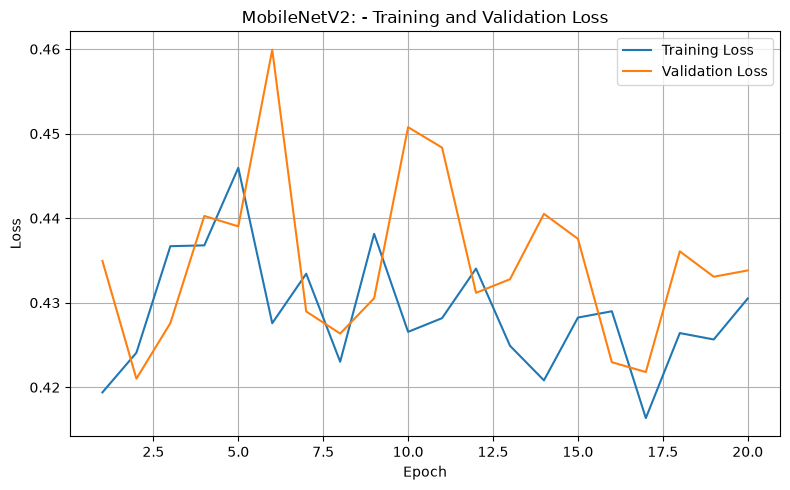

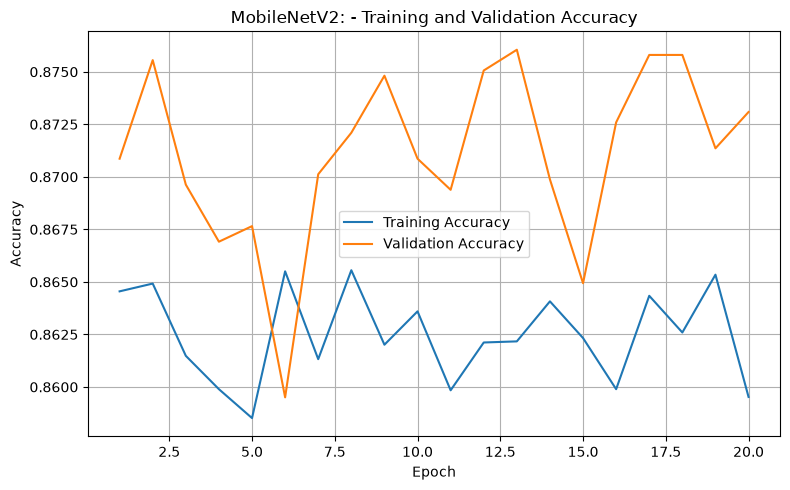

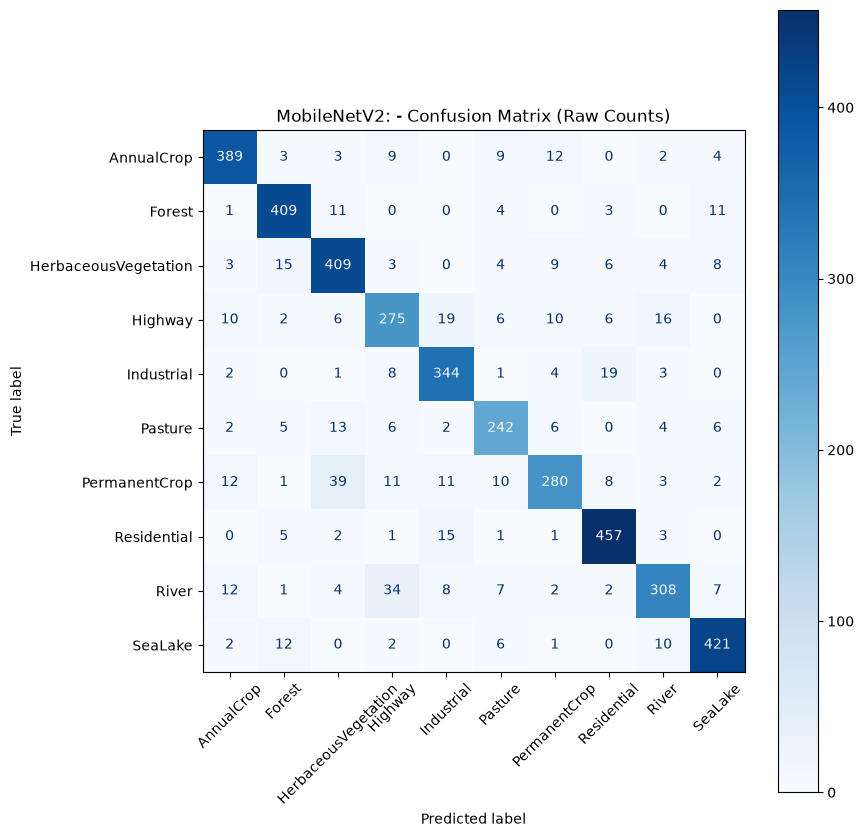


Visualizing SqueezeNet:...


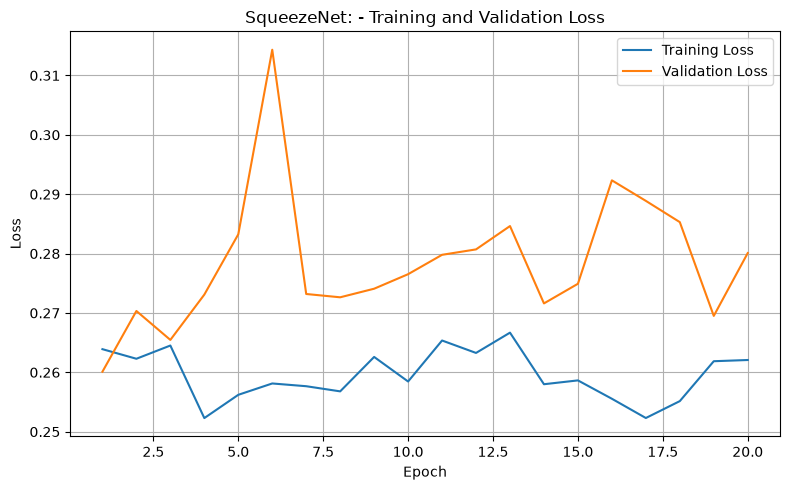

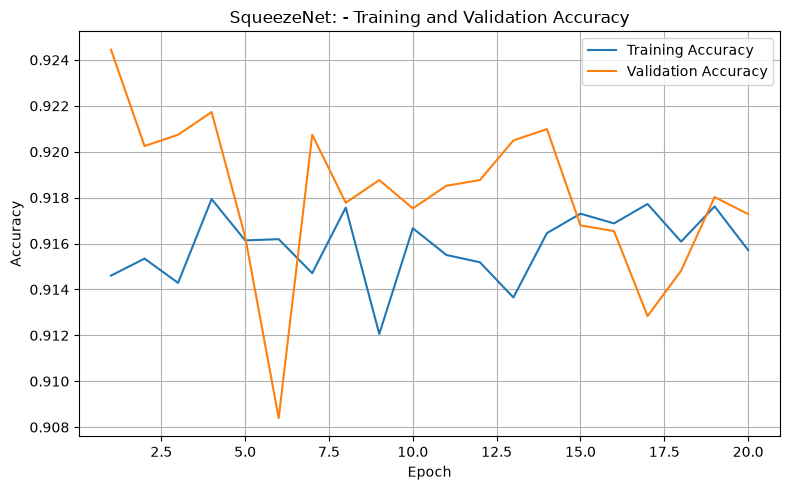

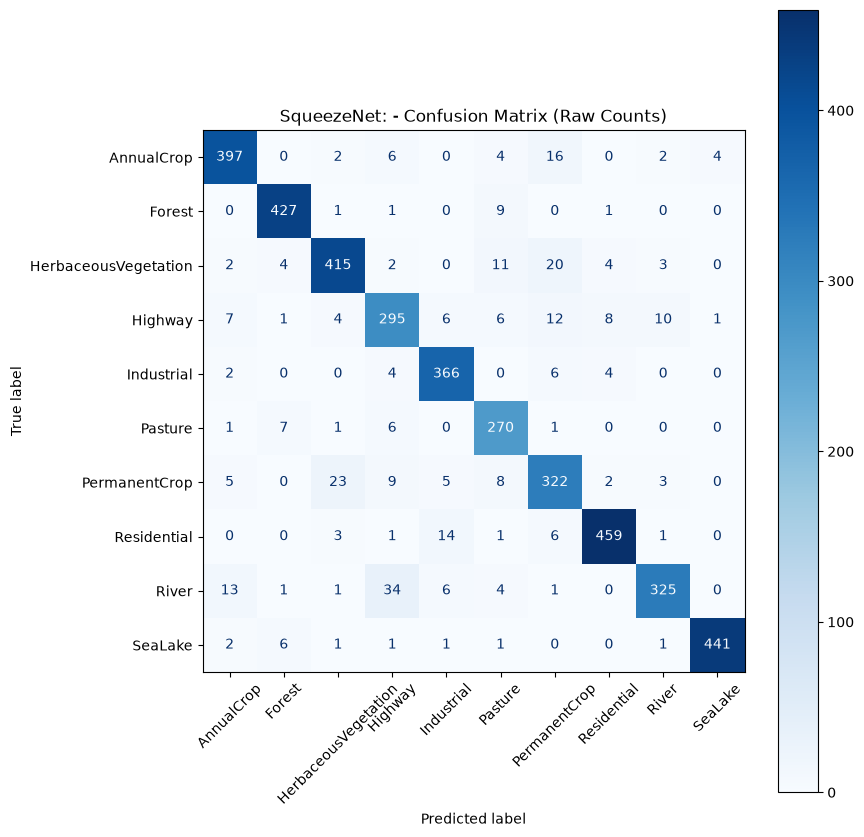

In [20]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
from utils import plot_training_history

for name in models_to_train.keys():
    print(f"\nVisualizing {name}...")
    
    # 1. Plot the Loss and Accuracy curves
    plot_training_history(results_dict[name]['history'], model_name=name)
    
    # 2. Extract the raw confusion matrix (which already contains the exact counts)
    cm_raw = results_dict[name]['confusion_matrix']
    
    # 3. Plot the raw counts directly
    display = ConfusionMatrixDisplay(
        confusion_matrix=cm_raw, 
        display_labels=classes
    )
    
    fig, ax = plt.subplots(figsize=(9, 9))
    display.plot(
        ax=ax, 
        xticks_rotation=45, 
        values_format="d",  # "d" formats the output as whole number counts
        cmap="Blues"
    )
    ax.set_title(f"{name} - Confusion Matrix (Raw Counts)")
    plt.tight_layout()
    plt.show()